# Legal-FAQ Retrieval Experiment（法律FAQ检索实验）

## 1. Install Packages（安装依赖）

In [1]:
import importlib.util
missing = [name for name in ['datasets', 'rank_bm25', 'sentence_transformers', 'torch', 'numpy', 'pandas', 'matplotlib'] if importlib.util.find_spec(name) is None]
if missing:
    raise ImportError('Select the Legal FAQ kernel or see README.md for package versions; missing: ' + ', '.join(missing))
print('Dependencies available; no automatic package upgrades.')

Dependencies available; no automatic package upgrades.


## 2. Imports and Settings（导入与参数）

In [2]:
import hashlib
import importlib.metadata
import json
import platform
import random
import re
import time
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from huggingface_hub import HfApi
from IPython.display import display
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer
from tqdm.auto import tqdm

SEED = 42
DATASET_ID = "nlpctx/legal-faq-paraphrased"
MODEL_ID = "BAAI/bge-small-en-v1.5"
DATASET_REVISION = "1e6d5276557ee6c05e554290e5270ef59d140111"
MODEL_REVISION = "5c38ec7c405ec4b44b94cc5a9bb96e735b38267a"
QUERY_TYPES = ["original", "formal", "casual", "search", "hard"]
QUERY_INSTRUCTION = "Represent this sentence for searching relevant passages: "
BM25_K1, BM25_B = 1.5, 0.75
RRF_CONSTANT = 60
ENCODE_BATCH_SIZE = 32
SCORE_BATCH_SIZE = 128
RECOMPUTE_RETRIEVAL = False
ROOT = Path.cwd()
OUTPUT_DIR = ROOT / ('legal_faq_rebuild' if RECOMPUTE_RETRIEVAL else 'legal_faq_results')
if RECOMPUTE_RETRIEVAL and (OUTPUT_DIR / 'run_metadata.json').exists():
    raise ValueError('Choose a new output directory for recomputation.')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
print("Device:", DEVICE)
print("Results:", OUTPUT_DIR.resolve())

from project_support import sha256
if not RECOMPUTE_RETRIEVAL:
    saved_metadata = json.loads((OUTPUT_DIR / 'run_metadata.json').read_text(encoding='utf-8'))
    saved_hashes = json.loads((ROOT / 'rag_formal' / 'manifest.json').read_text(encoding='utf-8'))['hashes']
    for filename, expected in {**saved_metadata['sha256'], **saved_hashes}.items():
        assert sha256(OUTPUT_DIR / filename) == expected, filename + ' integrity failure'
print('Recompute retrieval:', RECOMPUTE_RETRIEVAL)

Device: cuda
Results: C:\Users\lenovo\Desktop\888\project\legal_faq_results


Recompute retrieval: False


## 3. Load and Inspect Data（加载与检查数据）

In [3]:
if RECOMPUTE_RETRIEVAL:
    api = HfApi()
    dataset_commit = api.dataset_info(DATASET_ID, revision=DATASET_REVISION).sha
    model_commit = api.model_info(MODEL_ID, revision=MODEL_REVISION).sha
    dataset = load_dataset(DATASET_ID, split="train", revision=dataset_commit)
    print(dataset)
    print("Columns:", dataset.column_names)
    print("Schema:", dataset.features)
    raw_df = dataset.to_pandas()
    raw_df.to_csv(OUTPUT_DIR / "raw.csv", index=False, encoding="utf-8-sig")
    display(raw_df.head(3))
    display(pd.DataFrame({"dtype": raw_df.dtypes.astype(str), "missing": raw_df.isna().sum()}))
else:
    dataset_commit = saved_metadata['dataset_revision']
    model_commit = saved_metadata['model_revision']
    raw_df = pd.read_csv(OUTPUT_DIR / 'raw.csv')
    print('Pinned local raw data:', raw_df.shape)
    display(raw_df.head(3))
    display(raw_df.dtypes)

Pinned local raw data: (2090, 7)


,doc_id,question,answer,formal,casual,search,hard
0,0,What is the procedure to file an FIR in Tamil...,"Filing an FIR in Tamil Nadu:\nTo file an FIR,...",How can one lodge an FIR in the state of Tamil...,So how do I make a police report in Tamil Nadu?,What's the process for filing a complaint with...,How can I submit a police report in the Tamil ...
1,1,Can I file an FIR online in Tamil Nadu?,"Filing an FIR Online in Tamil Nadu:\nYes, you...",How can one file an FIR online in Tamil Nadu?,"Anyways, how do I file an FIR online in TN?",What's the process to file an online FIR in Ta...,Where can I submit an electronic report in Tam...
2,2,What information is required while filing an ...,Required Information for Filing an FIR:\nYou ...,What documentation is necessary for lodging an...,Need what to write an FIR?,What kind of info do I need to file an FIR?,What must be submitted when reporting a crime?


doc_id      int64
question      str
answer        str
formal        str
casual        str
search        str
hard          str
dtype: object

## 4. Validate and Build Corpus（验证与构建语料）

In [4]:
required_columns = ["doc_id", "question", "answer", "formal", "casual", "search", "hard"]
missing_columns = sorted(set(required_columns) - set(raw_df.columns))
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")
if raw_df.empty or raw_df[required_columns].isna().any().any():
    raise ValueError("Dataset is empty or required values are missing; inspect raw.csv.")

clean_df = raw_df[required_columns].copy()
clean_df["doc_id"] = clean_df["doc_id"].astype(str).str.strip()
for column in required_columns[1:]:
    if not clean_df[column].map(lambda value: isinstance(value, str)).all():
        raise TypeError(f"Non-text values in {column}; inspect the dataset.")
    clean_df[column] = clean_df[column].str.strip()
if clean_df.eq("").any().any():
    raise ValueError("Empty required values; inspect raw.csv.")
if clean_df["doc_id"].duplicated().any():
    raise ValueError("Repeated doc_id values require explicit resolution before evaluation.")

corpus = clean_df[["doc_id", "answer"]].rename(columns={"answer": "text"})
corpus = corpus.sort_values("doc_id", kind="stable").reset_index(drop=True)
duplicate_answers = corpus[corpus["text"].duplicated(keep=False)]
if RECOMPUTE_RETRIEVAL:
    duplicate_answers.to_csv(OUTPUT_DIR / "duplicate_answers.csv", index=False, encoding="utf-8-sig")
if RECOMPUTE_RETRIEVAL:
    corpus.to_csv(OUTPUT_DIR / "corpus.csv", index=False, encoding="utf-8-sig")
print(f"Corpus: {len(corpus):,} documents; rows sharing exact answer text: {len(duplicate_answers):,}")
display(corpus.head())
if not RECOMPUTE_RETRIEVAL:
    pd.testing.assert_frame_equal(corpus, pd.read_csv(OUTPUT_DIR / 'corpus.csv', dtype={'doc_id': str}))

Corpus: 2,090 documents; rows sharing exact answer text: 71


,doc_id,text
0,0,"Filing an FIR in Tamil Nadu:\nTo file an FIR, ..."
1,1,"Filing an FIR Online in Tamil Nadu:\nYes, you ..."
2,10,FIR Time Limit:\nThere is no specific time lim...
3,100,Reporting Child Abuse or Neglect:\nTo report c...
4,1000,"Tamil Nadu Police Mobile App\nTo use the app, ..."


## 5. Build Query Variants（构建查询变体）

In [5]:
query_columns = {"original": "question", "formal": "formal", "casual": "casual",
                 "search": "search", "hard": "hard"}
query_rows = []
for record in clean_df.sort_values("doc_id", kind="stable").to_dict("records"):
    for query_type, source_column in query_columns.items():
        query_rows.append({"query_id": f"Q{len(query_rows) + 1:06d}",
                           "doc_id": record["doc_id"], "query_type": query_type,
                           "query": record[source_column]})
queries = pd.DataFrame(query_rows, columns=["query_id", "doc_id", "query_type", "query"])
assert queries["query_id"].is_unique
assert len(queries) == 5 * len(corpus)
assert set(queries["doc_id"]) <= set(corpus["doc_id"])
if RECOMPUTE_RETRIEVAL:
    queries.to_csv(OUTPUT_DIR / "queries.csv", index=False, encoding="utf-8-sig")
duplicate_queries = queries[queries["query"].duplicated(keep=False)]
if RECOMPUTE_RETRIEVAL:
    duplicate_queries.to_csv(OUTPUT_DIR / "duplicate_queries.csv", index=False, encoding="utf-8-sig")
display(queries.head(10))
display(queries.groupby("query_type").size().reindex(QUERY_TYPES).rename("n_queries"))
print("Repeated query-text rows:", len(duplicate_queries))

doc_ids = corpus["doc_id"].to_numpy()
doc_to_index = {doc_id: index for index, doc_id in enumerate(doc_ids)}
gold_indices = queries["doc_id"].map(doc_to_index).to_numpy(dtype=np.int32)
NUM_DOCS, NUM_QUERIES = len(corpus), len(queries)
if not RECOMPUTE_RETRIEVAL:
    pd.testing.assert_frame_equal(queries, pd.read_csv(OUTPUT_DIR / 'queries.csv', dtype={'doc_id': str}))

,query_id,doc_id,query_type,query
0,Q000001,0,original,What is the procedure to file an FIR in Tamil ...
1,Q000002,0,formal,How can one lodge an FIR in the state of Tamil...
2,Q000003,0,casual,So how do I make a police report in Tamil Nadu?
3,Q000004,0,search,What's the process for filing a complaint with...
4,Q000005,0,hard,How can I submit a police report in the Tamil ...
5,Q000006,1,original,Can I file an FIR online in Tamil Nadu?
6,Q000007,1,formal,How can one file an FIR online in Tamil Nadu?
7,Q000008,1,casual,"Anyways, how do I file an FIR online in TN?"
8,Q000009,1,search,What's the process to file an online FIR in Ta...
9,Q000010,1,hard,Where can I submit an electronic report in Tam...


query_type
original    2090
formal      2090
casual      2090
search      2090
hard        2090
Name: n_queries, dtype: int64

Repeated query-text rows: 271


## 6. Evaluation Criteria（评价标准）

- 单一相关文档排名为 r：Recall@k = 1（r ≤ k），否则为 0；在此设置下等于 Hit@k。
- MRR = 所有查询的 1/r 的平均值，排名使用完整语料。
- nDCG@5 = 1/log₂(r + 1)（r ≤ 5），否则为 0。

In [6]:
METRICS = ["Recall@1", "Recall@5", "Recall@10", "MRR", "nDCG@5"]

def metrics_from_ranks(ranks):
    ranks = np.asarray(ranks, dtype=np.float64)
    if not np.isfinite(ranks).all() or (ranks < 1).any():
        raise ValueError("Gold ranks must be finite and at least one.")
    return pd.DataFrame({
        "Recall@1": (ranks <= 1).astype(float),
        "Recall@5": (ranks <= 5).astype(float),
        "Recall@10": (ranks <= 10).astype(float),
        "MRR": 1.0 / ranks,
        "nDCG@5": np.where(ranks <= 5, 1.0 / np.log2(ranks + 1), 0.0),
    })

def evaluate_rankings(rankings, method):
    if rankings.shape != (NUM_QUERIES, NUM_DOCS):
        raise ValueError("Expected a complete query-by-document ranking matrix.")
    expected = np.arange(NUM_DOCS)
    for start in range(0, NUM_QUERIES, SCORE_BATCH_SIZE):
        block = rankings[start:start + SCORE_BATCH_SIZE]
        if not np.all(np.sort(block, axis=1) == expected):
            raise ValueError("Invalid ranking permutation.")
    gold_ranks = np.argmax(rankings == gold_indices[:, None], axis=1) + 1
    detail = queries[["query_id", "doc_id", "query_type"]].copy()
    detail.insert(0, "method", method)
    detail["gold_rank"] = gold_ranks
    detail[METRICS] = metrics_from_ranks(gold_ranks)
    return detail

def summarize(detail):
    overall = detail.groupby("method", sort=False)[METRICS].mean().reset_index()
    overall.insert(1, "query_type", "overall")
    overall["n_queries"] = detail.groupby("method", sort=False).size().to_numpy()
    grouped = detail.groupby(["method", "query_type"], sort=False)[METRICS].mean().reset_index()
    counts = detail.groupby(["method", "query_type"], sort=False).size().reset_index(name="n_queries")
    grouped = grouped.merge(counts, on=["method", "query_type"], validate="one_to_one")
    return pd.concat([overall, grouped], ignore_index=True)

check = metrics_from_ranks([1, 2, 5, 10, 11])
np.testing.assert_allclose(check["MRR"], [1, 0.5, 0.2, 0.1, 1/11])
np.testing.assert_allclose(check["nDCG@5"], [1, 1/np.log2(3), 1/np.log2(6), 0, 0])
assert check["Recall@1"].sum() == 1
assert check["Recall@5"].sum() == 3
assert check["Recall@10"].sum() == 4
print("Metric checks passed.")
timings = []


Metric checks passed.


## 7. BM25 Retrieval（BM25检索）

In [7]:
if RECOMPUTE_RETRIEVAL:
    def tokenize(text):
        return re.findall(r"\b\w+\b", text.lower())

    started = time.perf_counter()
    tokenized_corpus = [tokenize(text) for text in corpus["text"]]
    if any(not tokens for tokens in tokenized_corpus):
        raise ValueError("A document has no BM25 tokens.")
    bm25 = BM25Okapi(tokenized_corpus, k1=BM25_K1, b=BM25_B)
    vocabulary = set(token for tokens in tokenized_corpus for token in tokens)
    bm25_rankings = np.empty((NUM_QUERIES, NUM_DOCS), dtype=np.int32)
    no_overlap = 0
    for query_index, query_text in enumerate(tqdm(queries["query"], desc="BM25")):
        tokens = tokenize(query_text)
        no_overlap += int(not vocabulary.intersection(tokens))
        scores = np.asarray(bm25.get_scores(tokens))
        bm25_rankings[query_index] = np.argsort(-scores, kind="stable")
    timings.append({"method": "BM25", "stage": "index_and_rank", "seconds": time.perf_counter() - started})
    bm25_detail = evaluate_rankings(bm25_rankings, "BM25")
    display(summarize(bm25_detail).round(4))
    print("Queries without vocabulary overlap:", no_overlap)
else:
    bm25_rankings = np.load(OUTPUT_DIR / 'bm25_full_rankings.npy', mmap_mode='r')
    bm25_detail = evaluate_rankings(bm25_rankings, 'Bm25')
    display(summarize(bm25_detail).round(4))

,method,query_type,Recall@1,Recall@5,Recall@10,MRR,nDCG@5,n_queries
0,Bm25,overall,0.4514,0.6332,0.6894,0.5355,0.5495,10450
1,Bm25,original,0.8574,0.9756,0.9909,0.9090,0.9241,2090
2,Bm25,formal,0.5507,0.7742,0.8220,0.6519,0.6742,2090
3,Bm25,casual,0.2038,0.3761,0.4593,0.2888,0.2944,2090
4,Bm25,search,0.4153,0.6411,0.7043,0.5164,0.5358,2090
5,Bm25,hard,0.2297,0.3990,0.4703,0.3112,0.3190,2090


## 8. Dense Retrieval（稠密检索）

In [8]:
if RECOMPUTE_RETRIEVAL:
    started = time.perf_counter()
    model = SentenceTransformer(MODEL_ID, revision=model_commit, device=DEVICE)
    dense_queries = [QUERY_INSTRUCTION + text for text in queries["query"]]

    def token_lengths(texts):
        lengths = []
        for start in range(0, len(texts), 256):
            encoded = model.tokenizer(texts[start:start + 256], truncation=False,
                                      padding=False, return_length=True)
            lengths.extend(encoded["length"])
        return np.asarray(lengths)

    document_lengths = token_lengths(corpus["text"].tolist())
    query_lengths = token_lengths(dense_queries)
    truncation_report = pd.DataFrame({
        "kind": ["documents", "queries_with_instruction"],
        "count": [NUM_DOCS, NUM_QUERIES],
        "max_tokens": [int(document_lengths.max()), int(query_lengths.max())],
        "over_model_limit": [int((document_lengths > model.max_seq_length).sum()),
                             int((query_lengths > model.max_seq_length).sum())],
        "model_limit": [model.max_seq_length, model.max_seq_length],
    })
    display(truncation_report)
    truncation_report.to_csv(OUTPUT_DIR / "truncation_report.csv", index=False)

    document_embeddings = model.encode(corpus["text"].tolist(), batch_size=ENCODE_BATCH_SIZE,
                                       normalize_embeddings=True, convert_to_numpy=True,
                                       show_progress_bar=True)
    query_embeddings = model.encode(dense_queries, batch_size=ENCODE_BATCH_SIZE,
                                    normalize_embeddings=True, convert_to_numpy=True,
                                    show_progress_bar=True)
    assert np.isfinite(document_embeddings).all() and np.isfinite(query_embeddings).all()
    timings.append({"method": "Dense", "stage": "load_audit_and_encode", "seconds": time.perf_counter() - started})

    started = time.perf_counter()
    dense_rankings = np.empty((NUM_QUERIES, NUM_DOCS), dtype=np.int32)
    for start in tqdm(range(0, NUM_QUERIES, SCORE_BATCH_SIZE), desc="Dense ranking"):
        stop = min(start + SCORE_BATCH_SIZE, NUM_QUERIES)
        scores = query_embeddings[start:stop] @ document_embeddings.T
        dense_rankings[start:stop] = np.argsort(-scores, axis=1, kind="stable")
    timings.append({"method": "Dense", "stage": "rank", "seconds": time.perf_counter() - started})
    dense_detail = evaluate_rankings(dense_rankings, "Dense")
    display(summarize(dense_detail).round(4))
else:
    dense_rankings = np.load(OUTPUT_DIR / 'dense_full_rankings.npy', mmap_mode='r')
    dense_detail = evaluate_rankings(dense_rankings, 'Dense')
    display(summarize(dense_detail).round(4))
    display(pd.read_csv(OUTPUT_DIR / 'truncation_report.csv'))

,method,query_type,Recall@1,Recall@5,Recall@10,MRR,nDCG@5,n_queries
0,Dense,overall,0.7255,0.9062,0.9378,0.8061,0.8263,10450
1,Dense,original,0.9177,0.9828,0.9861,0.9472,0.9555,2090
2,Dense,formal,0.7962,0.9483,0.9656,0.8649,0.8833,2090
3,Dense,casual,0.6258,0.8627,0.9043,0.7301,0.7563,2090
4,Dense,search,0.7287,0.9187,0.9507,0.8132,0.8351,2090
5,Dense,hard,0.5589,0.8187,0.8823,0.6751,0.7011,2090


,kind,count,max_tokens,over_model_limit,model_limit
0,documents,2090,298,0,512
1,queries_with_instruction,10450,41,0,512


## 9. RRF Hybrid Retrieval（RRF融合检索）

In [9]:
def fuse_rrf(first_order, second_order, constant=60):
    if constant <= 0:
        raise ValueError("RRF constant must be positive.")
    positions = np.arange(1, len(first_order) + 1, dtype=np.float64)
    first_ranks = np.empty(len(first_order), dtype=np.float64)
    second_ranks = np.empty(len(second_order), dtype=np.float64)
    first_ranks[first_order] = positions
    second_ranks[second_order] = positions
    fused_scores = 1.0 / (constant + first_ranks) + 1.0 / (constant + second_ranks)
    return np.argsort(-fused_scores, kind="stable")

np.testing.assert_array_equal(fuse_rrf(np.array([2, 0, 1]), np.array([2, 0, 1])), [2, 0, 1])
np.testing.assert_array_equal(fuse_rrf(np.array([0, 1]), np.array([1, 0])), [0, 1])
if RECOMPUTE_RETRIEVAL:
    started = time.perf_counter()
    hybrid_rankings = np.empty_like(bm25_rankings)
    for query_index in tqdm(range(NUM_QUERIES), desc="Hybrid RRF"):
        hybrid_rankings[query_index] = fuse_rrf(bm25_rankings[query_index],
                                              dense_rankings[query_index], RRF_CONSTANT)
    timings.append({"method": "Hybrid", "stage": "fusion_only", "seconds": time.perf_counter() - started})
    hybrid_detail = evaluate_rankings(hybrid_rankings, "Hybrid")
    display(summarize(hybrid_detail).round(4))
else:
    hybrid_rankings = np.load(OUTPUT_DIR / 'hybrid_full_rankings.npy', mmap_mode='r')
    hybrid_detail = evaluate_rankings(hybrid_rankings, 'Hybrid')
    display(summarize(hybrid_detail).round(4))

,method,query_type,Recall@1,Recall@5,Recall@10,MRR,nDCG@5,n_queries
0,Hybrid,overall,0.5869,0.7742,0.8355,0.6761,0.6889,10450
1,Hybrid,original,0.9110,0.9876,0.9923,0.9455,0.9556,2090
2,Hybrid,formal,0.6751,0.8737,0.9172,0.7660,0.7857,2090
3,Hybrid,casual,0.3933,0.6182,0.7249,0.5065,0.5143,2090
4,Hybrid,search,0.5718,0.7909,0.8541,0.6708,0.6890,2090
5,Hybrid,hard,0.3833,0.6005,0.6890,0.4917,0.4997,2090


## 10. Method Comparison（方法比较）

In [10]:
all_detail = pd.concat([bm25_detail, dense_detail, hybrid_detail], ignore_index=True)
all_summary = summarize(all_detail)
overall_results = all_summary[all_summary["query_type"] == "overall"].reset_index(drop=True)
by_type_results = all_summary[all_summary["query_type"] != "overall"].reset_index(drop=True)
method_order = ["BM25", "Dense", "Hybrid"]
print("RQ1: Overall comparison")
display(overall_results.round(4))
comparison_tables = {}
for metric in METRICS:
    table = by_type_results.pivot(index="query_type", columns="method", values=metric)
    table = table.reindex(index=QUERY_TYPES, columns=method_order)
    comparison_tables[metric] = table
    print(metric)
    display(table.round(4))

original_scores = by_type_results[by_type_results["query_type"] == "original"].set_index("method")
robustness = by_type_results[["method", "query_type", "n_queries"]].copy()
for metric in METRICS:
    robustness[f"delta_{metric}_vs_original"] = (
        by_type_results[metric] - by_type_results["method"].map(original_scores[metric]))
print("RQ2: Change relative to original queries (absolute metric units)")
display(robustness.round(4))

hybrid_gains = pd.DataFrame(index=pd.Index(QUERY_TYPES, name="query_type"))
for metric, table in comparison_tables.items():
    for baseline in ["BM25", "Dense"]:
        hybrid_gains[f"{metric}_Hybrid_minus_{baseline}"] = table["Hybrid"] - table[baseline]
print("RQ3: Hybrid gains; positive values favor Hybrid")
display(hybrid_gains.round(4))


RQ1: Overall comparison


,method,query_type,Recall@1,Recall@5,Recall@10,MRR,nDCG@5,n_queries
0,Bm25,overall,0.4514,0.6332,0.6894,0.5355,0.5495,10450
1,Dense,overall,0.7255,0.9062,0.9378,0.8061,0.8263,10450
2,Hybrid,overall,0.5869,0.7742,0.8355,0.6761,0.6889,10450


Recall@1


method,BM25,Dense,Hybrid
query_type,,,
original,NaN,0.9177,0.9110
formal,NaN,0.7962,0.6751
casual,NaN,0.6258,0.3933
search,NaN,0.7287,0.5718
hard,NaN,0.5589,0.3833


Recall@5


method,BM25,Dense,Hybrid
query_type,,,
original,NaN,0.9828,0.9876
formal,NaN,0.9483,0.8737
casual,NaN,0.8627,0.6182
search,NaN,0.9187,0.7909
hard,NaN,0.8187,0.6005


... (6 outputs left out)

RQ2: Change relative to original queries (absolute metric units)


,method,query_type,n_queries,delta_Recall@1_vs_original,delta_Recall@5_vs_original,delta_Recall@10_vs_original,delta_MRR_vs_original,delta_nDCG@5_vs_original
0,Bm25,original,2090,0.0000,0.0000,0.0000,0.0000,0.0000
1,Bm25,formal,2090,-0.3067,-0.2014,-0.1689,-0.2571,-0.2499
2,Bm25,casual,2090,-0.6536,-0.5995,-0.5316,-0.6202,-0.6296
3,Bm25,search,2090,-0.4421,-0.3344,-0.2866,-0.3927,-0.3883
4,Bm25,hard,2090,-0.6278,-0.5766,-0.5206,-0.5979,-0.6051
5,Dense,original,2090,0.0000,0.0000,0.0000,0.0000,0.0000
6,Dense,formal,2090,-0.1215,-0.0344,-0.0206,-0.0823,-0.0721
7,Dense,casual,2090,-0.2919,-0.1201,-0.0818,-0.2171,-0.1992
8,Dense,search,2090,-0.1890,-0.0641,-0.0354,-0.1340,-0.1204
9,Dense,hard,2090,-0.3589,-0.1641,-0.1038,-0.2721,-0.2544


RQ3: Hybrid gains; positive values favor Hybrid


,Recall@1_Hybrid_minus_BM25,Recall@1_Hybrid_minus_Dense,Recall@5_Hybrid_minus_BM25,Recall@5_Hybrid_minus_Dense,Recall@10_Hybrid_minus_BM25,Recall@10_Hybrid_minus_Dense,MRR_Hybrid_minus_BM25,MRR_Hybrid_minus_Dense,nDCG@5_Hybrid_minus_BM25,nDCG@5_Hybrid_minus_Dense
query_type,,,,,,,,,,
original,NaN,-0.0067,NaN,0.0048,NaN,0.0062,NaN,-0.0017,NaN,0.0001
formal,NaN,-0.1211,NaN,-0.0746,NaN,-0.0483,NaN,-0.0989,NaN,-0.0977
casual,NaN,-0.2325,NaN,-0.2445,NaN,-0.1794,NaN,-0.2237,NaN,-0.2420
search,NaN,-0.1569,NaN,-0.1278,NaN,-0.0967,NaN,-0.1424,NaN,-0.1461
hard,NaN,-0.1756,NaN,-0.2182,NaN,-0.1933,NaN,-0.1833,NaN,-0.2014


## 11. Result Visualization（结果可视化）

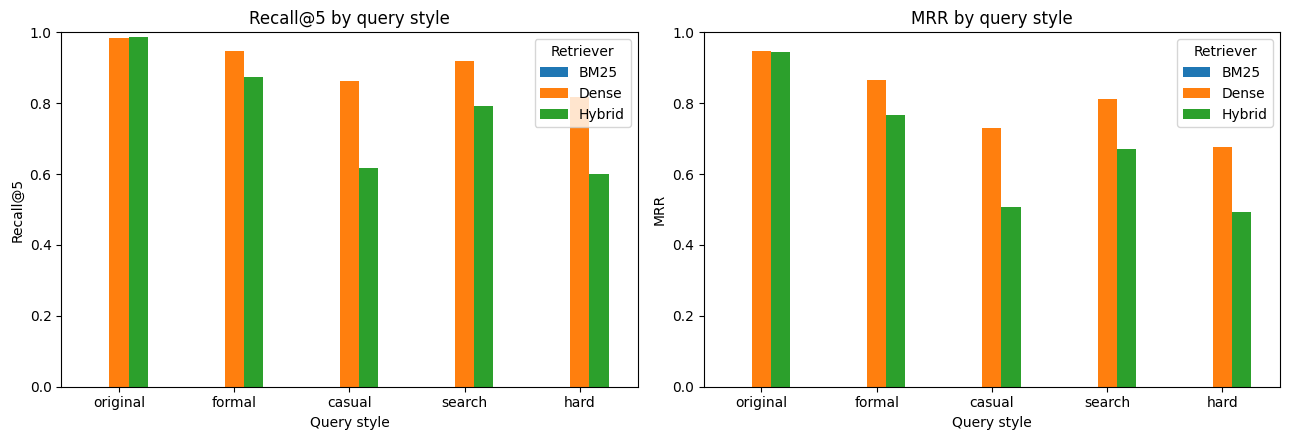

In [11]:
figure, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for axis, metric in zip(axes, ["Recall@5", "MRR"]):
    comparison_tables[metric].plot.bar(ax=axis, rot=0)
    axis.set_title(f"{metric} by query style")
    axis.set_xlabel("Query style")
    axis.set_ylabel(metric)
    axis.set_ylim(0, 1)
    axis.legend(title="Retriever")
figure.tight_layout()
figure.savefig(OUTPUT_DIR / "retrieval_comparison.png", dpi=200, bbox_inches="tight")
plt.show()


## 12. Export Results（导出结果）

In [12]:
all_detail.to_csv(OUTPUT_DIR / "per_query_metrics.csv", index=False, encoding="utf-8-sig")
all_summary.to_csv(OUTPUT_DIR / "all_metrics.csv", index=False, encoding="utf-8-sig")
overall_results.to_csv(OUTPUT_DIR / "overall_results.csv", index=False, encoding="utf-8-sig")
by_type_results.to_csv(OUTPUT_DIR / "results_by_query_type.csv", index=False, encoding="utf-8-sig")
robustness.to_csv(OUTPUT_DIR / "robustness_vs_original.csv", index=False, encoding="utf-8-sig")
hybrid_gains.to_csv(OUTPUT_DIR / "hybrid_gains.csv", encoding="utf-8-sig")
if RECOMPUTE_RETRIEVAL:
    pd.DataFrame(timings).to_csv(OUTPUT_DIR / "stage_timings.csv", index=False)
for metric, table in comparison_tables.items():
    table.to_csv(OUTPUT_DIR / f"comparison_{metric.replace('@', '_at_')}.csv", encoding="utf-8-sig")

if RECOMPUTE_RETRIEVAL:
    rankings_by_method = {"BM25": bm25_rankings, "Dense": dense_rankings, "Hybrid": hybrid_rankings}
    top_rows = []
    for method, rankings in rankings_by_method.items():
        np.save(OUTPUT_DIR / f"{method.lower()}_full_rankings.npy", rankings)
        for query_index in range(NUM_QUERIES):
            for rank, corpus_index in enumerate(rankings[query_index, :10], start=1):
                top_rows.append({"method": method, "query_id": queries.iloc[query_index]["query_id"],
                                 "rank": rank, "retrieved_doc_id": doc_ids[corpus_index],
                                 "is_gold": bool(corpus_index == gold_indices[query_index])})
    pd.DataFrame(top_rows).to_csv(OUTPUT_DIR / "top10_retrievals.csv", index=False, encoding="utf-8-sig")

    packages = ["datasets", "rank-bm25", "sentence-transformers", "transformers", "torch",
                "numpy", "pandas", "matplotlib", "huggingface-hub", "tqdm"]
    versions = {package: importlib.metadata.version(package) for package in packages}
    metadata = {
        "created_utc": datetime.now(timezone.utc).isoformat(), "seed": SEED,
        "dataset": DATASET_ID, "dataset_revision": dataset_commit, "split": "train",
        "dataset_fingerprint": dataset._fingerprint,
        "model": MODEL_ID, "model_revision": model_commit, "device": DEVICE,
        "python": platform.python_version(), "platform": platform.platform(),
        "versions": versions, "n_documents": NUM_DOCS, "n_queries": NUM_QUERIES,
        "corpus_text": "answer only", "query_types": QUERY_TYPES,
        "query_instruction": QUERY_INSTRUCTION, "max_sequence_length": model.max_seq_length,
        "normalize_embeddings": True, "bm25_k1": BM25_K1, "bm25_b": BM25_B,
        "bm25_tokenizer": "lowercase unicode word tokens; no stemming or stopword removal",
        "rrf_constant": RRF_CONSTANT, "rrf_depth": "full corpus", "rrf_weights": [1, 1],
        "mrr_depth": "full corpus", "tie_break": "lexicographic string doc_id corpus order",
        "encode_batch_size": ENCODE_BATCH_SIZE, "score_batch_size": SCORE_BATCH_SIZE,
        "bm25_no_overlap_queries": no_overlap,
        "sha256": {name: hashlib.sha256((OUTPUT_DIR / name).read_bytes()).hexdigest()
                   for name in ["raw.csv", "corpus.csv", "queries.csv"]},
    }
    (OUTPUT_DIR / "run_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
    (OUTPUT_DIR / "requirements_used.txt").write_text(
        "\n".join(f"{package}=={version}" for package, version in versions.items()) + "\n", encoding="utf-8")
assert len(overall_results) == 3 and len(by_type_results) == 15
assert len(all_detail) == 3 * NUM_QUERIES
assert all_detail[METRICS].ge(0).all().all() and all_detail[METRICS].le(1).all().all()
print("Completed. Results saved to:", OUTPUT_DIR.resolve())
display(pd.DataFrame({"file": sorted(path.name for path in OUTPUT_DIR.iterdir() if path.is_file())}))


Completed. Results saved to: C:\Users\lenovo\Desktop\888\project\legal_faq_results


,file
0,all_metrics.csv
1,bm25_full_rankings.npy
2,comparison_MRR.csv
3,comparison_Recall_at_1.csv
4,comparison_Recall_at_10.csv
5,comparison_Recall_at_5.csv
6,comparison_nDCG_at_5.csv
7,corpus.csv
8,dense_full_rankings.npy
9,duplicate_answers.csv
